### State Definition

In [ ]:
import operator
from typing import Literal, List, NewType
from pydantic import BaseModel, Field 
from typing import Annotated, Optional
from typing_extensions import TypedDict

# from langgraph.graph.message import add_messages


# String = NewType('String', str)
# Boolean = NewType("Boolean", bool)i

class UserQuery(BaseModel):
    """State to manage user query"""
    query: str = Field(..., description="An user query for learn a language")
    query_language: Literal["German"] = Field(
                                    "German",
                                    description="The language used for the query given")
    translated_language: Literal["English"] = Field(
                                    "English", description="The language used to translate the query")

# class UserQuery(BaseModel):
#     """State to manage user query"""
#     # verb: str
#     adjective: str


class LanguageClass(BaseModel):
    verbs: List[str] = Field(..., description="A list of verbs of a given query")
    adjectives: List[str] = Field(..., description="A list of adjectives of a given query")
    adverbs: List[str] = Field(..., description="A list of adjectives of a given query")
    prepositions: List[str] = Field(..., description="A list of prepositions of a given query")
    nouns: List[str] = Field(..., description="A list of nouns of a given query")
    conjunctions: List[str] = Field(..., description="A list of conjunctions of a given query")
    interjections: List[str] = Field(..., description="A list of interjections of a given query")
    translated_query: str = Field(None,
                            description="""A translated query on 
                            the given user query""")
    
    

class PartOfSpeech(BaseModel):
    """State to manage part of speech"""
    verbs: List[str] = Field(..., description="A list of verbs of a given query")
    adjectives: List[str] = Field(..., description="A list of adjectives of a given query")
    adverbs: List[str] = Field(..., description="A list of adjectives of a given query")
    prepositions: List[str] = Field(..., description="A list of prepositions of a given query")
    nouns: List[str] = Field(..., description="A list of nouns of a given query")
    conjunctions: List[str] = Field(..., description="A list of conjunctions of a given query")
    interjections: List[str] = Field(..., description="A list of interjections of a given query")


class Cases(BaseModel):
    """State to manage all the cases"""
    speech: str = Field(..., description="""A identifier of a speech whether
                    it is a direct, indirect or possesion""")


class Translation(BaseModel):
    """State to manage translation of given query"""
    translated_query: str = Field(...,
                            description="""A translated query on 
                            the given user query""")


class GermanAdverbDetails(BaseModel):
    adverb: str = Field(..., description="The German adverb")
    english_translation: str = Field(..., description="English translation of the adverb")
    adverb_type: Optional[
        Literal["modal", "temporal", "local", "causal", "manner", "degree"]
    ] = Field(None, description="Type of adverb (e.g., temporal, modal, etc.)")
    is_comparable: bool = Field(..., description="True if the adverb can be compared")

class GermanPrepositionDetails(BaseModel):
    word: str = Field(..., description="The German preposition")
    english_translation: str = Field(..., description="English translation of the preposition")
    case_governed: Literal["accusative", "dative", "genitive", "mixed"] = Field(
        ..., description="Which grammatical case(s) the preposition governs"
    )
    preposition_type: Optional[Literal["local", "temporal", "modal", "causal"]] = Field(
        None, description="Type of preposition"
    )


# class GermanVerbsDetails(BaseModel):
#     """State to manage conjugation of single verb given"""
#     infinitive: List[str] = Field(...,
#                             description="""An Infintive form of 
#                             the given string in German
#                             """)
#     # infinitive: str = Field(...,
#     #                         description="""An Infintive form of 
#     #                         the given string in German
#     #                         """)
    
#     singular_present_tense: List[str] = Field(...,
#                             description="""The 3rd person singular used in present tense
#                             for the given verb in German. 
#                             """)
#     simple_past: List[str] = Field(...,
#                              description="""The simple past for the given verb in German. 
#                              """)
#     present_perfect: List[str] = Field(...,
#                              description="""The present perfect tense for the given verb in German.
#                              """)
#     english_alternative: List[str] = Field(...,
#                              description="""The English translation for the given verb. 
#                              """)

class GermanVerbsDetails(BaseModel):
    """State to manage conjugation of single verb given"""
    infinitive: str = Field(...,
                            description="""An Infintive form of 
                            the given string in German
                            """)
    # infinitive: String = Field(...,
    #                         description="""An Infintive form of 
    #                         the given string in German
    #                         """)
    
    singular_present_tense: List[str] = Field(...,
                            description="""The 3rd person singular used in present tense
                            for the given verb in German. 
                            """)
    simple_past: List[str] = Field(...,
                             description="""The simple past for the given verb in German. 
                             """)
    present_perfect: List[str] = Field(...,
                             description="""The present perfect tense for the given verb in German.
                             """)
    # is_separable: Boolean
    # is_separable: Boolean = Field(...,
    #                            description="""Wheather the verb is separable or inseparable? True
    #                            if it's seperable else False
    #                            """)
    # # is_regular: Boolean
    # is_regular: Boolean = Field(...,
    #                          description=""" Whather the verb is regular or irregular verb? True if
    #                          it's regular else False""")
    is_separable: bool = Field(...,
                               description="""Wheather the verb is separable or inseparable? True
                               if it's seperable else False
                               """)
    # is_regular: Boolean
    is_regular: bool = Field(...,
                             description=""" Whather the verb is regular or irregular verb? True if
                             it's regular else False""")
    
    english_alternative: List[str] = Field(...,
                             description="""The English translation for the given verb. 
                             """)

class GermanAdjectiveDetails(BaseModel):
    """Details about a comparable German adjective."""

    positive: str = Field(
        ...,
        description="The base (positive) form of the German adjective."
    )

    comparative: str = Field(
        ...,
        description="The comparative form of the German adjective."
    )

    superlative: str = Field(
        ...,
        description="The superlative form of the German adjective."
    )

    english_translation: str = Field(
        ...,
        description="The English translation of the German adjective."
    )    

    is_regular: bool = Field(
        ...,
        description="Whether the adjective follows regular comparative and superlative formation rules. True if regular, else False."
    )
    
    is_comparable: bool = Field(
        ...,
        description="Whether the adjective is gradable (can form comparative and superlative). True if comparable, else False."
    )


class GermanNounDetails(BaseModel):
    """Details about a German noun."""

    noun: str = Field(
        ...,
        description="The base form (singular) of the German noun."
    )

    plural: str = Field(
        ...,
        description="The plural form of the German noun."
    )

    gender: str = Field(
        ...,
        description="The grammatical gender of the noun (der, die, das)."
    )

    case_forms: Optional[dict] = Field(
        None,
        description="A dictionary of case forms for the noun. Includes nominative, accusative, dative, and genitive."
    )

    english_translation: Optional[str] = Field(
        None,
        description="The English translation of the German noun."
    )

    is_irregular: Optional[bool] = Field(
        None,
        description="Whether the noun follows irregular pluralization rules (True) or regular rules (False)."
    )

class GermanConjunctionDetails(BaseModel):
    conj: str = Field(..., description="The German conjunction")
    english_translation: str = Field(..., description="English translation of the conjunction")
    conjunction_type: Literal["coordinating", "subordinating", "correlative"] = Field(
        ..., description="Type of conjunction"
    )
    # affects_word_order: bool = Field(
    #     ..., description="True if it changes the word order (typically subordinating)"
    # )

    
class GermanGrammerDetails(BaseModel):
    """State to manage detailed grammer """
    verbs_info: Annotated[List[dict], operator.add] = Field(None,
                            description="""A detailed german verb information
                            such as infinitive, singular_present_tense, simple_past,
                            present_perfect and english_alternative.
                            """)
    adjectives_info: Annotated[List[dict], operator.add] = Field(None,
                        description="""A detailed german adjective information.
                        """)
    nouns_info: Annotated[List[dict], operator.add] = Field(None,
                        description="""A detailed german noun information.
                        """)
    
    conjunctions_info: Annotated[List[dict], operator.add] = Field(None,
                        description="""A detailed german conjuctions information.
                        """)
    adverbs_info: Annotated[List[dict], operator.add] = Field(None,
                        description="""A detailed german adverb information.
                        """)
    prepositions_info: Annotated[List[dict], operator.add] = Field(None,
                        description="""A detailed german preposition information.
                        """)
    

                        



In [2]:
type(PartOfSpeech)

pydantic._internal._model_construction.ModelMetaclass

In [3]:
type(Translation)

pydantic._internal._model_construction.ModelMetaclass

### POS Prompts 

In [ ]:
from typing import Optional
from pydantic._internal._model_construction import ModelMetaclass
from langchain.output_parsers import PydanticOutputParser
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.output_parsers import YamlOutputParser
from langchain_core.output_parsers import JsonOutputParser

class SysPrompts:

    def __init__(self):
        pass

    def get_pos_quey(self,
                     pydantic_format: Optional[ModelMetaclass] = None
                     ):
        """ """
        pos_query = """You are a precise and reliable linguistic parser.
        
        Your task is to extract specific parts of speech from a given query (1 - 5 sentences)
        . Only return words **explicitly present** in the input text, and do not infer or hallucinate any words.
        
        **Requirements:**
        - Do not include any word that is not in the input.
        - If a category is not found, return an empty list.
        - Do not return explanations or extra text—only the structured data in JSON format.
        - Treat proper nouns as nouns.
        - Use lowercase for all words in the output lists.
        
        """
        if pydantic_format:
            pos_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            pos_query_format = pos_parser.get_format_instructions()
            pos_query += f"Instructions:\n{pos_query_format}"
        
        pos_sys_query = SystemMessage(pos_query)
        return (pos_parser, pos_sys_query)

    def get_translation_query(self,
                              src: str = Literal["German"],
                              dest: str = Literal["English"],
                              pydantic_format: Optional[ModelMetaclass] = None
                              ):
        """ """
        translation_query = f"""You are a precise and professional {src}-to-{dest} translator.
        
        Your task is to translate a given sentence or short paragraph from German to natural, fluent English. The output should:
        
        - Preserve the original meaning exactly.
        - Avoid adding or removing any information.
        - Use correct English grammar and idiomatic expressions where appropriate.
        - Be limited to only what was present in the German input—do not explain or interpret.
        """
        if pydantic_format:
            translation_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            translation_query_format = translation_parser.get_format_instructions()
            translation_query += f"Instructions:\n{translation_query_format}"
            
        trans_sys_query = SystemMessage(translation_query)
        return (translation_parser, trans_sys_query)

    def get_verb_conjugations(self,
                              pydantic_format: Optional[ModelMetaclass] = None
                              ):
        """ """
        verb_conj_query = f"""You are a professional German language grammar assistant.
        For the given German verb, provide a structured morphological breakdown covering
        commonly used tenses and forms. Your response should be clear, concise, and learner-friendly.

        Instructions:
        - Do not provide any explanation — just the required words.
        - Provide the informtaion in german
        - Do not hallucinate or invent forms.
        - Just Give True or False for Regular and Seperable Verb 
        - Do not include markdown formatting or any extra text — return only valid JSON.
        - Return booleans as true/false (not in lists).
        - The infinitive must be a single string, not a list.
        - Set "is_regular" to False if the verb has a vowel change in the stem between 
          infinitive and any of its conjugated forms (especially simple past or present).

        - Set "is_separable" to True if the verb begins with a separable prefix,
          such as: ab-, an-, auf-, aus-, bei-, ein-, mit-, nach-, vor-, weg-, zu-,
          and forms like aufstehen become steht ... auf in use.
        
        Give the following informations:
        
tting or any extra text — return only valid JSON.the simple past (Präteritum) could be multiple in German
        4. Give the Present Perfect (Perfekt) could be multiple in German
        5. Give the english translate for the given verb
        6. Is it a regular verb answer it in bool
        7. Is it a seperable verb answer it in bool
        
        Example:
        verb: spiele
        1. spielen
        2. [spielt]
        3. [spielte]
        4. [hat gespielt]
        5. [play]
        6. True
        7. False
        
        """

        # verb_conj_query = """You are a professional German language grammar assistant.
        # For the given German verb, provide a structured morphological breakdown covering commonly used tenses and forms.
        
        # Instructions:
        # - Do not provide any explanation — just the required words.
        # - Provide all information in German, except the English translation (point 5).
        # - Do not hallucinate or invent forms.
        # - For points 6 and 7, return only True or False.
        
        # Required Information Format:
        # 1. Provide the Infinitive of the verb (just one string)
        # 2. Provide the singular present tense forms (can be multiple)
        # 3. Provide the simple past (Präteritum) forms (can be multiple)
        # 4. Provide the present perfect (Perfekt) forms (can be multiple)
        # 5. Provide the English translation of the verb
        # 6. Is it a regular verb? (True/False)
        # 7. Is it a separable verb? (True/False)

        #  Example:
        # verb: spiele
        # 1. spielen
        # 2. [spielt]
        # 3. [spielte]
        # 4. [hat gespielt]
        # 5. [play]
        # 6. True
        # 7. False
        # """
        if pydantic_format:
            verb_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            # verb_parser = YamlOutputParser(pydantic_object=pydantic_format)
            # verb_parser = JsonOutputParser(pydantic_object=pydantic_format)
            verb_query_format = verb_parser.get_format_instructions()
            verb_conj_query += f"Instructions:\n{verb_query_format}"
            
        verb_cnj_sys_query = SystemMessage(verb_conj_query)
        return (verb_parser, verb_cnj_sys_query)

    def get_adjectives_query(self,
                       pydantic_format: Optional[ModelMetaclass] = None
                       ):
        """ """
        adj_query = """
        You are a professional German language grammar assistant.
        For the given German adjective, provide a structured morphological breakdown that includes its comparative and superlative forms.
        
        Instructions:
        - Do not provide any explanation — just the required words.
        - Provide the information in German.
        - Do not hallucinate or invent forms.
        - Only include adjectives that are regular and comparable.
        - Do not include markdown formatting or any extra text — return only valid JSON.
        - Return booleans as true/false (not in lists).
        - The positive, comparative, and superlative forms must be single strings (not in lists).
        - The English translation must be a single string.
        
        Provide the following information:
        
        1. The positive form (base form) of the adjective as a string
        2. The comparative form as a string
        3. The superlative form as a string (e.g. "am schönsten / der/die/das schönste")
        4. The English translation as a string
        5. Is it a regular adjective (true/false)
        6. Is it comparable (true/false)
        
        Example:
        
        Input: schön
        
        Output:
        {
          "positive": "schön",
          "comparative": "schöner",
          "superlative": "am schönsten / der/die/das schönste",
          "english_translation": "beautiful",
          "is_regular": true,
          "is_comparable": true
        }
        """
        if pydantic_format:
            adj_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            # verb_parser = YamlOutputParser(pydantic_object=pydantic_format)
            # verb_parser = JsonOutputParser(pydantic_object=GermanVerbsDetails)
            adj_query_format = adj_parser.get_format_instructions()
            adj_query += f"Instructions:\n{adj_query_format}"
            
        adj_sys_query = SystemMessage(adj_query)
        return (adj_parser, adj_sys_query)

    def get_noun_query(self,
                       pydantic_format: Optional[ModelMetaclass] = None
                       ):
        """ """
        noun_query = """You are a professional German language grammar assistant.

        For the given German noun, return a **structured JSON object** describing its grammatical features.
        
        Instructions:
        - Do not include markdown formatting or any extra text — return only **valid JSON**.
        - Do not include numbered keys like "1. Singular" or "2. Plural" — only use the exact field names provided.
        - Booleans must be returned as `true` or `false`, not strings.
        - Case forms must be a nested JSON object with keys: "nominative", "accusative", "dative", "genitive"
        - The output must be a valid JSON object directly compatible with a Pydantic model.

        Provide the noun details in the following format:
        
        Noun: Haus
        1. Singular: Haus
        2. Plural: Häuser
        3. Gender: das
        4. Case forms: {"nominative": "Haus", "accusative": "Haus", "dative": "Haus", "genitive": "Hauses"}
        5. English: house
        6. Is irregular: True
        """
        if pydantic_format:
            noun_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            # verb_parser = YamlOutputParser(pydantic_object=pydantic_format)
            # verb_parser = JsonOutputParser(pydantic_object=GermanVerbsDetails)
            noun_query_format = noun_parser.get_format_instructions()
            noun_query += f"Instructions:\n{noun_query_format}"
            
            noun_sys_query = SystemMessage(noun_query)
            return (noun_parser, noun_sys_query)
        
        noun_sys_query = SystemMessage(noun_query)
        return (None, noun_sys_query)

    def get_adverb_query(self,
                       pydantic_format: Optional[ModelMetaclass] = None
                       ):
        adverb_query = """You are a professional German language grammar assistant.

        For the given German adverb, return a structured JSON object describing its grammatical features.
        
        Instructions:
        - Do not include markdown formatting or any extra text — return only valid JSON.
        - Only use the exact field names provided below — no additional or numbered keys.
        - Booleans must be returned as true or false, not strings.
        - The value of adverb_type must be one of: "temporal", "local", "modal", "causal", "manner", or "degree". If the type is unclear, set it to null.
        
        The output must be a valid JSON object directly compatible with the following structure:
            
            {
              "adverb": "string",                        // The German adverb
              "english_translation": "string",           // English translation of the adverb
              "adverb_type": "temporal" | "local" | "modal" | "causal" | "manner" | "degree" | null,
              "is_comparable": true | false              // Whether the adverb is comparable
            }
             
        """
        if pydantic_format:
            adverb_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            adverb_query_format = adverb_parser.get_format_instructions()
            adverb_query += f"Instructions:\n{adverb_query_format}"
            
            adverb_sys_query = SystemMessage(adverb_query)
            return (adverb_parser, adverb_sys_query)
        
        adverb_sys_query = SystemMessage(adverb_query)
        return (None, adverb_sys_query)
        
    def get_preposition_query(self,
                       pydantic_format: Optional[ModelMetaclass] = None
                       ):
        preposition_query = """
        You are a professional German language grammar assistant.

        For the given German preposition, return a structured JSON object describing its grammatical features.
        
        Instructions:
         - Do not include markdown formatting or any extra text — return only valid JSON.
         - Only use the exact field names provided — do not add numbering or additional labels.
         - Booleans must be returned as true or false, not strings.
         - The field case_governed must be one of: "accusative", "dative", "genitive", or "mixed" depending on the preposition’s use.
         - The output must be a valid JSON object directly compatible with a Pydantic model.
         - Return the case_governed as accusative, dative, genitive or mixed
         - Return the preposition_type as local, temporal, modal or causal

        """
        if pydantic_format:
            preposition_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            preposition_query_format = preposition_parser.get_format_instructions()
            # preposition_query_format = GermanPrepositionDetails.model_json_schema()
            preposition_query += f"Instructions:\n{preposition_query_format}"
            
            preposition_sys_query = SystemMessage(preposition_query)
            return (preposition_parser, preposition_sys_query)
        
        noun_sys_query = SystemMessage(noun_query)
        return (None, noun_sys_query)
        
    def get_conjuction_query(self,
                       pydantic_format: Optional[ModelMetaclass] = None
                       ):
        conjuction_query = """You are a professional German language grammar assistant.

        For the given German conjunction, return a structured JSON object describing its grammatical features.
        
        Instructions:
        - Do not include markdown formatting or any extra text — return only valid JSON.
        - Only use the exact field names provided — do not add numbering or additional labels.
        - The field conjunction_type must be one of: "coordinating", "subordinating", or "correlative".
        - The output must be a valid JSON object directly compatible with a Pydantic model.
        - the value of conjunction_type must be correlative, coordinating or subordinating
    
        """
        if pydantic_format:
            conjuction_parser = PydanticOutputParser(pydantic_object=pydantic_format)
            conjuction_query_format = conjuction_parser.get_format_instructions()
            conjuction_query += f"Instructions:\n{conjuction_query_format}"
            
            conjuction_sys_query = SystemMessage(conjuction_query)
            return (conjuction_parser, conjuction_sys_query)
        
        conjuction_sys_query = SystemMessage(conjuction_query)
        return (None, conjuction_sys_query)     
# **Output (English):**
# (Only the translated sentence. No additional text.""")
# pos_format_sys_query = SystemMessage(pos_query_format)


NameError: name 'Literal' is not defined

### Models

In [5]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.1",
    temperature=0,
    num_threads=29,
    num_gpu=0
 )
# response = llm.invoke("hey")
# print(type(response))


### Nodes

In [22]:
from trustcall import create_extractor
from langgraph.prebuilt import create_react_agent
class Nodes:
    def __init__(self):
        self.sys_prompt = SysPrompts()
        
    def part_of_speech(self, state: UserQuery) -> LanguageClass:
        """ """
        parser, pos_sys_query = self.sys_prompt.get_pos_quey(
                            pydantic_format=PartOfSpeech)
        
        query = state.query
        pos_usr_query = HumanMessage(f"Query: {query}")


        # bound = create_extractor(
        #                     llm,
        #                     tools=[PartOfSpeech],
        #                     tool_choice="PartOfSpeech",
        #                 )

        response = llm.invoke([pos_sys_query, pos_usr_query])
        formated_response = parser.invoke(response)
        # formated_response = (response["responses"][0])
        return formated_response.model_dump()
        # return {"verbs": []}
        
    def translation(self, state: UserQuery) -> LanguageClass:
        """ """
        query = state.query
        translation_usr_query = HumanMessage(f"Input (German): {query}")

        
        original_language = state.query_language
        translated_language = state.translated_language
        parser, translation_sys_query = self.sys_prompt.get_translation_query(
                            src=original_language,
                            dest=translated_language,
                            pydantic_format=Translation)
        
        response = llm.invoke([translation_sys_query, translation_usr_query])
        formated_response = parser.invoke(response)
        return {"translated_query": formated_response.model_dump()}

    def send_queries(self, state: PartOfSpeech):
        """Condition to send queries to youtube_searcher node"""
        # queries = eval(state["enhanced_queries"])<
        verbs = state.verbs
        adjectives = state.adjectives
        adverbs = state.adverbs
        nouns = state.nouns
        
        verbs_state = [Send("Verb Conjugation", {"verb": verb})
                       for verb in verbs]
        adjectives = [Send("Adjective", {"adjective": adjective})
                       for adjective in adjectives]
        # adverbs = [Send("Adverb", {"adverb": adverb})
        #                for adverb in adverbs]
        # prepositions = [Send("verb_conjugation", {"verb": verb})
        #                for verb in verbs]
        nouns = [Send("Noun", {"noun": noun})
                       for noun in nouns]
                       
        # conjunctions = [Send("verb_conjugation", {"verb": verb})
        #                for verb in verbs]
        # interjections = [Send("verb_conjugation", {"verb": verb})
        #                for verb in verbs]
        verbs_state.extend(adjectives)
        verbs_state.extend(adverbs)
        verbs_state.extend(nouns)
        # print(verbs_state)
        return verbs_state
    

    
    # def verb_conjugation(self, state: PartOfSpeech) ->  GermanGrammerDetails:
    def verb_conjugation(self, state:UserQuery) ->  GermanGrammerDetails:
        """ """
        verb = state["verb"]
        # verb = state.verb
        verb_usr_query = HumanMessage(f"Verb : {verb}")
        parser, verb_conj_sys_query = self.sys_prompt.get_verb_conjugations(
                            pydantic_format=GermanVerbsDetails)

        # from langchain_community.tools import DuckDuckGoSearchRun
        # from langchain_community.tools import DuckDuckGoSearchResults
        # ddg_raw_tool = DuckDuckGoSearchResults(output_format="string")
        
        # agent = create_react_agent(llm, [ddg_raw_tool])
        # response = agent.invoke([verb_conj_sys_query, verb_usr_query])
        # print(response)
        
        response = llm.invoke([verb_conj_sys_query, verb_usr_query])
        
        # output_parser = JsonOutputParser()
        # formated_response =  output_parser.invoke(response)


        
        formated_response = parser.invoke(response)
        
        # formated_response = parser.parse(response.content)
        # print(formated_response)
        
        # bound = create_extractor(
        #                     llm,
        #                     tools=[GermanVerbsDetails],
        #                     tool_choice="GermanVerbsDetails",
        #                 )

        # response = bound.invoke([verb_conj_sys_query, verb_usr_query])
        # print(response)
        # formated_response = (response["responses"][0])
        # return formated_response.model_dump()
        return {"verbs_info": [formated_response.model_dump()]}
    
    # def adjective(self, state: PartOfSpeech) ->  GermanGrammerDetails:
    def adjective(self, state: UserQuery) ->  GermanGrammerDetails:
        """ """
        adj = state["adjective"]
        # adj = state.adjective
        
        adj_usr_query = HumanMessage(f"Adjective : {adj}")
        parser, adj_sys_query = self.sys_prompt.get_adjectives_query(
                            pydantic_format=GermanAdjectiveDetails)
        
        response = llm.invoke([adj_sys_query, adj_usr_query])
        formated_response = parser.invoke(response)
        # formated_response = parser.parse(response.content)
        return {"adjectives_info": [formated_response.model_dump()]}

    def noun(self, state: UserQuery) ->  GermanGrammerDetails:
        """ """
        noun = state["noun"]
        # noun = state.noun
        
        noun_usr_query = HumanMessage(f"Noun : {noun}")
        parser, noun_sys_query = self.sys_prompt.get_noun_query(
                            pydantic_format=GermanNounDetails)
        
        response = llm.invoke([noun_sys_query, noun_usr_query])
        if parser:
            formated_response = parser.invoke(response)
        # TODO
        # formated_response = parser.parse(response.content)
        return {"nouns_info": [formated_response.model_dump()]}

    def adverbs(self, state: UserQuery) ->  GermanGrammerDetails:
        """ """
        adverb = state["adverb"]
        # adverb = state.adverb
        
        adverb_usr_query = HumanMessage(f"Adverb : {adverb}")
        parser, adverb_sys_query = self.sys_prompt.get_adverb_query(
                            pydantic_format=GermanAdverbDetails)
        
        response = llm.invoke([adverb_sys_query, adverb_usr_query])
        if parser:
            formated_response = parser.invoke(response)
        # TODO
        # formated_response = parser.parse(response.content)
        return {"adverbs_info": [formated_response.model_dump()]}

    def prepositions(self, state: UserQuery) ->  GermanGrammerDetails:
        """ """
        preposition = state["preposition"]
        # preposition = state.prep
        
        preposition_usr_query = HumanMessage(f"Prepostion : {preposition}")
        parser, preposition_sys_query = self.sys_prompt.get_preposition_query(
                            pydantic_format=GermanPrepositionDetails)
        response = llm.invoke([preposition_sys_query, preposition_usr_query])
        if parser:
            formated_response = parser.invoke(response)
        # TODO
        # formated_response = parser.parse(response.content)
        return {"prepositions_info": [formated_response.model_dump()]}

    def conjunctions(self, state: UserQuery) ->  GermanGrammerDetails:
        """ """
        # print(state)
        conjunction = state["conjunction"]
        # conjuction = state.conjunction
        
        conjunction_usr_query = HumanMessage(f"Conjunction : {conjunction}")
        parser, conjunction_sys_query = self.sys_prompt.get_conjuction_query(
                            pydantic_format=GermanConjunctionDetails)
         
        response = llm.invoke([conjunction_sys_query, conjunction_usr_query])
        if parser:
            formated_response = parser.invoke(response)
            
        # TODO
        # formated_response = parser.parse(response.content)
        return {"conjunctions_info": [formated_response.model_dump()]}


In [23]:
# grammer_teacher = StateGraph()
# grammer_teacher

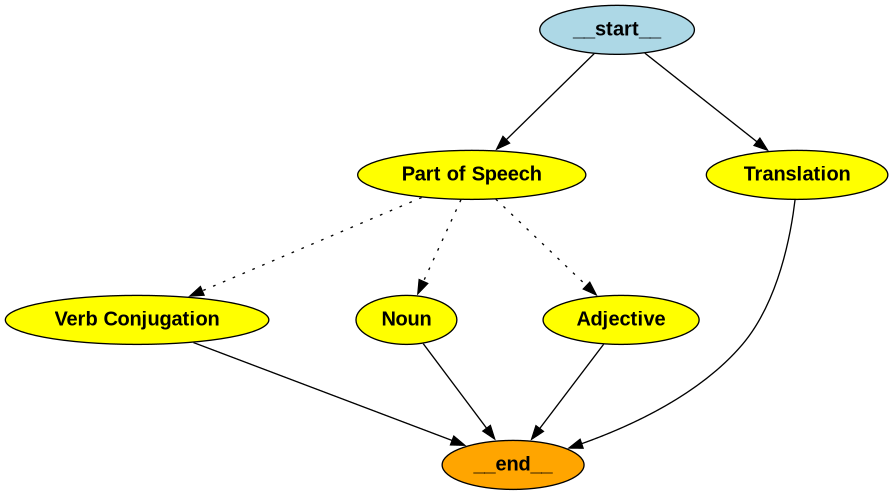

In [24]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()


builder = StateGraph(GermanGrammerDetails, input=UserQuery)
# builder = StateGraph(GermanGrammerDetails, )
# builder = StateGraph(PartOfSpeech, input=UserQuery)

builder.add_node("Part of Speech", nodes.part_of_speech)
# builder.add_node("
# builder.add_node("finalizer", nodes.finalizer)

builder.add_edge(START, "Part of Speech")
# builder.add_edge("Part of Speech", END)




# builder.add_edge("part_of_speech", "verb_conjugation")
# builder.add_edge("part_of_speech", "finalizer")


# builder.add_edge(START, "Translation")
# builder.add_node("Translation", nodes.translation)
# builder.add_edge("Translation", END)



# builder.add_node("Adverb", nodes.adverbs)
# builder.add_edge("Adverb", END)

builder.add_node("Verb Conjugation", nodes.verb_conjugation)
# builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation"])

# builder.add_edge(START, "Verb Conjugation")
builder.add_edge("Verb Conjugation", END)

builder.add_node("Noun", nodes.noun)



builder.add_node("Adjective", nodes.adjective)
builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation", "Adjective", "Noun"])
builder.add_edge("Adjective", END)
builder.add_edge("Noun", END)


# builder.add_edge(START, "translation")
# builder.add_edge("translation", "finalizer")

# builder.add_edge("finalizer", END)

memory = MemorySaver()
# app = builder.compile(checkpointer=memory, interrupt_before=["finalizer"])
app = builder.compile()

display(Image(app.get_graph().draw_png()))

In [25]:
response = app.invoke({"query":
    "Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. "})

In [26]:
response

{'verbs_info': [{'infinitive': 'begegnen',
   'singular_present_tense': ['begegnet'],
   'simple_past': ['begegnete'],
   'present_perfect': ['hat begegnet'],
   'is_separable': False,
   'is_regular': False,
   'english_alternative': ['met', 'encountered']},
  {'infinitive': 'bieten',
   'singular_present_tense': ['bietet'],
   'simple_past': ['bot'],
   'present_perfect': ['hat geboten'],
   'is_separable': False,
   'is_regular': True,
   'english_alternative': ['offers']}],
 'adjectives_info': [{'positive': 'ukrainisch',
   'comparative': 'ukrainischer',
   'superlative': 'am ukrainischsten / der/die/das Ukrainischste',
   'english_translation': 'Ukrainian',
   'is_regular': True,
   'is_comparable': False},
  {'positive': 'viel',
   'comparative': 'viel mehr / der/die/das Vielmehrige',
   'superlative': 'am meisten / das Meiste',
   'english_translation': 'much',
   'is_regular': False,
   'is_comparable': True},
  {'positive': 'eigen',
   'comparative': 'eigener',
   'superlative

### Adverb

In [323]:
from pydantic import BaseModel, Field
from typing import Optional, Literal


class GermanAdverbDetails(BaseModel):
    adverb: str = Field(..., description="The German adverb")
    english_translation: str = Field(..., description="English translation of the adverb")
    adverb_type: Optional[
        Literal["modal", "temporal", "local", "causal", "manner", "degree"]
    ] = Field(None, description="Type of adverb (e.g., temporal, modal, etc.)")
    is_comparable: bool = Field(..., description="True if the adverb can be compared")


class UserQuery(BaseModel):
    """State to manage user query"""
    # verb: str
    adverb: str


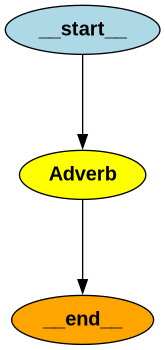

In [324]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()

builder = StateGraph(GermanGrammerDetails, input=UserQuery)

builder.add_node("Adverb", nodes.adverbs)
builder.add_edge(START, "Adverb")
builder.add_edge("Adverb", END)

memory = MemorySaver()
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [325]:

adverbs = ["heute", "morgen", "gestern", "bald", "jetzt", "sofort", "immer", "nie"
    "gern", "nicht", "vielleicht", "natürlich", "bestimmt"
    "hier", "dort", "oben", "unten", "überall", "nirgendwo"
    "deshalb", "darum", "deswegen", "aus diesem Grund"
    "so", "anders", "gemeinsam", "laut", "leise"
    "sehr", "ziemlich", "etwas", "kaum", "nur"]


for adverb in adverbs:
    response = app.invoke({"adverb": adverb})
    print(response)

{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [{'adverb': 'heute', 'english_translation': 'today', 'adverb_type': 'temporal', 'is_comparable': False}], 'prepositions': []}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [{'adverb': 'morgen', 'english_translation': 'tomorrow', 'adverb_type': 'temporal', 'is_comparable': False}], 'prepositions': []}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [{'adverb': 'gestern', 'english_translation': 'yesterday', 'adverb_type': 'temporal', 'is_comparable': False}], 'prepositions': []}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [{'adverb': 'bald', 'english_translation': 'soon', 'adverb_type': 'temporal', 'is_comparable': False}], 'prepositions': []}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [{'adverb': 'jetzt', 'english_translation': 'now', 'adverb_type': 'temporal', 'is_comparable': False}], 'pre

### Preposition

In [303]:
 class UserQuery(BaseModel):
    """State to manage user query"""
    # verb: str
    prep: str

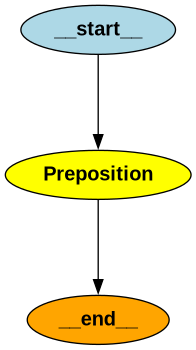

In [304]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()

builder = StateGraph(GermanGrammerDetails, input=UserQuery)

builder.add_node("Preposition", nodes.prepositions)
builder.add_edge(START, "Preposition")
builder.add_edge("Preposition", END)

memory = MemorySaver()
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [305]:
prepositions = ["durch", "für", "gegen", "ohne", "um", "aus", "bei", "mit", "nach", "seit", "von", "zu", "gegenüber","während", "trotz", "wegen", "anstatt", "innerhalb", "außerhalb", "an", "auf", "hinter", "in", "neben", "über", "unter", "vor", "zwischen"]


for prepo in prepositions:
    response = app.invoke({"prep": prepo})
    print(response)
    # print(response["conjunctions"])

{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [], 'prepositions': [{'word': 'durch', 'english_translation': 'through, by means of', 'case_governed': 'accusative', 'preposition_type': 'causal'}]}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [], 'prepositions': [{'word': 'für', 'english_translation': 'for', 'case_governed': 'accusative', 'preposition_type': 'causal'}]}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [], 'prepositions': [{'word': 'gegen', 'english_translation': 'against', 'case_governed': 'accusative', 'preposition_type': 'causal'}]}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [], 'prepositions': [{'word': 'ohne', 'english_translation': 'without', 'case_governed': 'accusative', 'preposition_type': 'modal'}]}
{'verbs': [], 'adjectives': [], 'nouns': [], 'conjunctions': [], 'adverbs': [], 'prepositions': [{'word': 'um', 'english_translation': 'around, abo

### Conjunction

In [255]:
class GermanConjunctionDetails(BaseModel):
    conj: str = Field(..., description="The German conjunction")
    english_translation: str = Field(..., description="English translation of the conjunction")
    conjunction_type: Literal["coordinating", "subordinating", "correlative"] = Field(
        ..., description="Type of conjunction"
    )
    # affects_word_order: bool = Field(
    #     ..., description="True if it changes the word order (typically subordinating)"
    # )
    
class UserQuery(BaseModel):
    """State to manage user query"""
    # verb: str
    conjunction: str

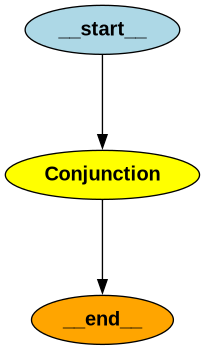

In [256]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()

builder = StateGraph(GermanGrammerDetails, input=UserQuery)

builder.add_node("Conjunction", nodes.conjunctions)
builder.add_edge(START, "Conjunction")
builder.add_edge("Conjunction", END)

memory = MemorySaver()
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [257]:
conjunctions = [
    "und", "oder", "aber", "denn", "sondern",
    "weil", "dass", "obwohl", "wenn", "während",
    "entweder ... oder", "sowohl ... als auch",
    "weder ... noch", "nicht nur ... sondern auch"
]
for conjunction in conjunctions:
    response = app.invoke({"conjunction": conjunction})
    print(response["conjunctions"])

conjunction='und'
[{'conj': 'und', 'english_translation': 'and', 'conjunction_type': 'coordinating'}]
conjunction='oder'
[{'conj': 'oder', 'english_translation': 'or', 'conjunction_type': 'coordinating'}]
conjunction='aber'
[{'conj': 'aber', 'english_translation': 'but', 'conjunction_type': 'correlative'}]
conjunction='denn'
[{'conj': 'denn', 'english_translation': 'for', 'conjunction_type': 'subordinating'}]
conjunction='sondern'
[{'conj': 'sondern', 'english_translation': 'but', 'conjunction_type': 'correlative'}]
conjunction='weil'
[{'conj': 'weil', 'english_translation': 'because', 'conjunction_type': 'subordinating'}]
conjunction='dass'
[{'conj': 'dass', 'english_translation': 'that', 'conjunction_type': 'subordinating'}]
conjunction='obwohl'
[{'conj': 'obwohl', 'english_translation': 'although', 'conjunction_type': 'subordinating'}]
conjunction='wenn'
[{'conj': 'wenn', 'english_translation': 'if', 'conjunction_type': 'subordinating'}]
conjunction='während'
[{'conj': 'während', 'e


### Nouns

In [ ]:
class GermanNounDetails(BaseModel):
    """Details about a German noun."""

    noun: str = Field(
        ...,
        description="The base form (singular) of the German noun."
    )

    plural: str = Field(
        ...,
        description="The plural form of the German noun."
    )

    gender: str = Field(
        ...,
        description="The grammatical gender of the noun (der, die, das)."
    )

    case_forms: Optional[dict] = Field(
        None,
        description="A dictionary of case forms for the noun. Includes nominative, accusative, dative, and genitive."
    )

    english_translation: Optional[str] = Field(
        None,
        description="The English translation of the German noun."
    )

    is_irregular: Optional[bool] = Field(
        None,
        description="Whether the noun follows irregular pluralization rules (True) or regular rules (False)."
    )


class UserQuery(BaseModel):
    """State to manage user query"""
    # verb: str
    noun: str

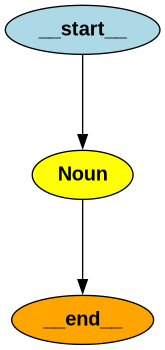

In [174]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()


builder = StateGraph(GermanGrammerDetails, input=UserQuery)

builder.add_node("Noun", nodes.noun)
builder.add_edge(START, "Noun")
builder.add_edge("Noun", END)

memory = MemorySaver()
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [176]:
nouns = [
    "Haus",
    "Hund",
    "Frau",
    "Kind",
    "Auto",
    "Tisch",
    "Stuhl",
    "Buch",
    "Mensch",
    "Freund"
]
for noun in nouns:
    response = app.invoke({"noun": noun})
    print(response["nouns"])

[{'noun': 'Haus', 'plural': 'Häuser', 'gender': 'das', 'case_forms': {'nominative': 'Haus', 'accusative': 'Haus', 'dative': 'Haus', 'genitive': 'Hauses'}, 'english_translation': 'house', 'is_irregular': True}]
[{'noun': 'Hund', 'plural': 'Hunde', 'gender': 'der', 'case_forms': {'nominative': 'Hund', 'accusative': 'Hunden', 'dative': 'Hundem', 'genitive': 'Hunds'}, 'english_translation': 'dog', 'is_irregular': False}]
[{'noun': 'Frau', 'plural': 'Frauen', 'gender': 'die', 'case_forms': {'nominative': 'Frau', 'accusative': 'Frau', 'dative': 'Frau', 'genitive': 'Frauen'}, 'english_translation': 'woman', 'is_irregular': False}]
[{'noun': 'Kind', 'plural': 'Kinder', 'gender': 'das', 'case_forms': {'nominative': 'Kind', 'accusative': 'Kind', 'dative': 'Kinde', 'genitive': 'Kindes'}, 'english_translation': 'child', 'is_irregular': False}]
[{'noun': 'Auto', 'plural': 'Autos', 'gender': 'das', 'case_forms': {'nominative': 'Auto', 'accusative': 'Auto', 'dative': 'Auto', 'genitive': 'Autos'}, 'en

### Adjectives

In [ ]:

class UserQuery(BaseModel):
    """State to manage user query"""
    # verb: str
    adjective: str

class GermanAdjectiveDetails(BaseModel):
    """Details about a comparable German adjective."""

    positive: str = Field(
        ...,
        description="The base (positive) form of the German adjective."
    )

    comparative: str = Field(
        ...,
        description="The comparative form of the German adjective."
    )

    superlative: str = Field(
        ...,
        description="The superlative form of the German adjective."
    )

    english_translation: str = Field(
        ...,
        description="The English translation of the German adjective."
    )
    is_regular: bool = Field(
    ...,
    description="Whether the adjective follows regular comparative and superlative formation rules. True if regular, else False."
    )
    
    is_comparable: bool = Field(
        ...,
        description="Whether the adjective is gradable (can form comparative and superlative). True if comparable, else False."
    )

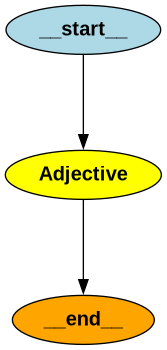

In [118]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()


builder = StateGraph(GermanGrammerDetails, input=UserQuery)
# builder = StateGraph(GermanGrammerDetails, )
# builder = StateGraph(PartOfSpeech, input=UserQuery)

# builder.add_node("Part of Speech", nodes.part_of_speech)
# builder.add_node("
# builder.add_node("finalizer", nodes.finalizer)

# builder.add_edge(START, "Part of Speech")
# builder.add_edge("Part of Speech", END)




# builder.add_edge("part_of_speech", "verb_conjugation")
# builder.add_edge("part_of_speech", "finalizer")


# builder.add_edge(START, "Translation")
# builder.add_node("Translation", nodes.translation)
# builder.add_edge("Translation", END)


# builder.add_node("Verb Conjugation", nodes.verb_conjugation)
# builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation"])

# builder.add_edge(START, "Verb Conjugation")
# builder.add_edge("Verb Conjugation", END)


builder.add_node("Adjective", nodes.adjective)
builder.add_edge(START, "Adjective")
# builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation", "Adjective"])
builder.add_edge("Adjective", END)


# builder.add_edge(START, "translation")
# builder.add_edge("translation", "finalizer")

# builder.add_edge("finalizer", END)

memory = MemorySaver()
# app = builder.compile(checkpointer=memory, interrupt_before=["finalizer"])
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [119]:
adjectives = [
    "gut",
    "schlecht",
    "groß",
    "klein",
    "schön",
    "alt",
    "jung",
    "neu",
    "lang",
    "kurz",
    "schnell",
    "langsam",
    "teuer",
    "billig",
    "freundlich",
    "nett",
    "laut",
    "leise",
    "stark",
    "schwach"
]
for adj in adjectives:
    response = app.invoke({"adjective": adj})
    print(response)

{'verbs': [], 'adjectives': [{'positive': 'gut', 'comparative': 'besser', 'superlative': 'am besten / der/die/das beste', 'english_translation': 'good', 'is_regular': True, 'is_comparable': True}]}
{'verbs': [], 'adjectives': [{'positive': 'schlecht', 'comparative': 'schlechter', 'superlative': 'am schlechtesten / der/die/das Schlechteste', 'english_translation': 'bad', 'is_regular': True, 'is_comparable': True}]}
{'verbs': [], 'adjectives': [{'positive': 'groß', 'comparative': 'größer', 'superlative': 'am größten / der/die/das Größte', 'english_translation': 'large', 'is_regular': True, 'is_comparable': True}]}
{'verbs': [], 'adjectives': [{'positive': 'klein', 'comparative': 'kleiner', 'superlative': 'am kleinsten / der/die/das kleinste', 'english_translation': 'small', 'is_regular': True, 'is_comparable': True}]}
{'verbs': [], 'adjectives': [{'positive': 'schön', 'comparative': 'schöner', 'superlative': 'am schönsten / der/die/das schönste', 'english_translation': 'beautiful', 'is_r

### Verbs

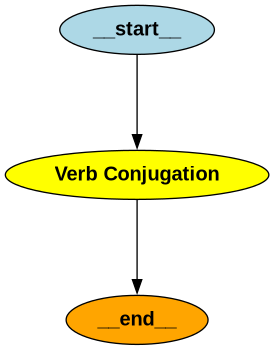

In [22]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START

from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Send

nodes = Nodes()

class UserQuery(BaseModel):
    """State to manage user query"""
    verb: str
    # adjective: str
    
builder = StateGraph(GermanGrammerDetails, input=UserQuery)
# builder = StateGraph(GermanGrammerDetails, )
# builder = StateGraph(PartOfSpeech, input=UserQuery)

# builder.add_node("Part of Speech", nodes.part_of_speech)
# builder.add_node("
# builder.add_node("finalizer", nodes.finalizer)

# builder.add_edge(START, "Part of Speech")
# builder.add_edge("Part of Speech", END)




# builder.add_edge("part_of_speech", "verb_conjugation")
# builder.add_edge("part_of_speech", "finalizer")


# builder.add_edge(START, "Translation")
# builder.add_node("Translation", nodes.translation)
# builder.add_edge("Translation", END)


builder.add_node("Verb Conjugation", nodes.verb_conjugation)
# builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation"])

builder.add_edge(START, "Verb Conjugation")
builder.add_edge("Verb Conjugation", END)


# builder.add_node("Adjective", nodes.adjective)
# builder.add_conditional_edges("Part of Speech", nodes.send_queries, ["Verb Conjugation", "Adjective"])
# builder.add_edge("Adjective", END)


# builder.add_edge(START, "translation")
# builder.add_edge("translation", "finalizer")

# builder.add_edge("finalizer", END)

memory = MemorySaver()
# app = builder.compile(checkpointer=memory, interrupt_before=["finalizer"])
app = builder.compile()

display(Image(app.get_graph().draw_png()))


In [23]:
verbs = [
    "machen",
    "gehen",
    "aufstehen",
    "lernen",
    "sehen",
    "mitbringen",
    "begegnen",
    "fahren",
    "spielen",
    "anfangen",
    "haben",
    "nehmen",
    "lesen",
    "aussteigen",
    "sagen",
    "denken",
    "verlieren",
    "schreiben",
    "kaufen",
    "dürfen"
]
for verb in verbs:
    response = app.invoke({"verb": verb})
    print(response)
    break

InvalidUpdateError: Expected dict, got [SystemMessage(content='You are a professional German language grammar assistant.\n        For the given German verb, provide a structured morphological breakdown covering\n        commonly used tenses and forms. Your response should be clear, concise, and learner-friendly.\n\n        Instructions:\n        - Do not provide any explanation — just the required words.\n        - Provide the informtaion in german\n        - Do not hallucinate or invent forms.\n        - Just Give True or False for Regular and Seperable Verb \n        - Do not include markdown formatting or any extra text — return only valid JSON.\n        - Return booleans as true/false (not in lists).\n        - The infinitive must be a single string, not a list.\n        - Set "is_regular" to False if the verb has a vowel change in the stem between \n          infinitive and any of its conjugated forms (especially simple past or present).\n\n        - Set "is_separable" to True if 

In [ ]:
response = app.invoke({"query":
    "Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. "})

In [ ]:
response

In [ ]:
query = "Mit dem Tod von Papst Franziskus werden im Vatikan die bevorstehenden Trauerfeierlichkeiten vorbereitet. "
response = app.invoke({"query": query})

In [ ]:
response

In [ ]:
query = "Sedisvakanz wird die Zeitspanne bis zur Wahl des neuen Papstes bezeichnet. Die Dauer lässt sich nicht genau vorhersagen"
response = app.invoke({"query": query})

In [ ]:
query = "Am Ablauf wurde über die Jahrhunderte immer wieder etwas geändert, aber die großen Linien stehen fest. Der Tod wird vom Camerlengo, dem Kardinalkämmerer, gemeinsam mit den Ärzten festgestellt. Camerlengo ist derzeit der irisch-US-amerikanische Kardinal Kevin Farrell"
response = app.invoke({"query": query})

In [ ]:
thread = {"configurable": {"thread_id": "1"}}
for each in app.stream({"query":
    "Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. "}, thread, stream_mode="values"):
    print(each)

In [ ]:
for event in app.stream(None, thread, stream_mode="values"):
    print(event)

In [57]:
for event in app.stream(None, thread, stream_mode="values"):
    print(event)

{'verbs': ['begegnet', 'bietet'], 'adjectives': ['ukrainische', 'viel', 'eigenes'], 'adverbs': [], 'prepositions': ['mit', 'an'], 'nouns': ['Initiative', 'Präsident', 'Land', 'Misstrauen', 'Kooperation'], 'conjunctions': ['aber'], 'interjections': [], 'query': 'Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. ', 'translated_query': "The Ukrainian President meets Putin's initiative with great distrust, but at the same time offers cooperation from his country."}


In [58]:
for event in app.stream(None, thread, stream_mode="values"):
    print(event)

{'verbs': ['begegnet', 'bietet'], 'adjectives': ['ukrainische', 'viel', 'eigenes'], 'adverbs': [], 'prepositions': ['mit', 'an'], 'nouns': ['Initiative', 'Präsident', 'Land', 'Misstrauen', 'Kooperation'], 'conjunctions': ['aber'], 'interjections': [], 'query': 'Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. ', 'translated_query': "The Ukrainian President meets Putin's initiative with great distrust, but at the same time offers cooperation from his country."}


In [60]:
app.get_state(thread).values

{'verbs': ['begegnet', 'bietet'],
 'adjectives': ['ukrainische', 'viel', 'eigenes'],
 'adverbs': [],
 'prepositions': ['mit', 'an'],
 'nouns': ['Initiative', 'Präsident', 'Land', 'Misstrauen', 'Kooperation'],
 'conjunctions': ['aber'],
 'interjections': [],
 'query': 'Der ukrainische Präsident begegnet der Initiative Putins mit viel Misstrauen, bietet zugleich aber die Kooperation seines Landes an. ',
 'translated_query': "The Ukrainian President meets Putin's initiative with great distrust, but at the same time offers cooperation from his country."}

In [57]:
response['verbs']

['begegnet', 'bietet']